# Fase 3: Construção do Grafo Direcionado e Métricas Topológicas

Na Fase 2 (`02_eda_e_auditoria.ipynb`), provamos que olhar para transações de forma isolada nos dá indícios valiosos, mas esbarra na cegueira estrutural do crime. 

Em vez de processar mais de 500 mil nós (o que geraria estouro de memória e uma "bola de pelo" ilegível), vamos extrair uma **sub-rede estratégica de alto risco**: o foco será em todas as transações ilícitas (`Is_Laundering = 1`) e seus vizinhos diretos de 1º grau. 

Sobre essa rede, construiremos um **Grafo Direcionado** via `NetworkX` e calcularemos métricas topológicas (*PageRank*, *Betweenness Centrality*, além dos graus de entrada e saída) para expor a anatomia dos anéis criminosos, identificando coletores, dispersores e as contas-laranja (*mule accounts*).

#### Extração da Sub-Rede de Risco via SQLite

Para garantir performance e isolar o comportamento dos fraudadores sem poluir a memória com contas totalmente desconectadas, faremos uma consulta que puxa apenas o núcleo quente do ecossistema transacional ilícito.

In [8]:
import sqlite3
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Conectando ao banco SQLite
DB_PATH = "../data/aml_network.db"
conn = sqlite3.connect(DB_PATH)

print("Conectado ao banco para leitura e montagem do Grafo.")

# Configuração de estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 8)

print("Extraindo a sub-rede de risco do banco SQLite.")

# Query: Pega transações ilícitas E transações que tocam contas envolvidas em fraude
query_sub_rede = """
    SELECT 
        Timestamp, 
        From_Bank, 
        Account, 
        To_Bank, 
        "Account.1" as Target_Account, 
        Amount_Paid, 
        Payment_Format, 
        Is_Laundering
    FROM transacoes
    WHERE Account IN (SELECT Account FROM transacoes WHERE Is_Laundering = 1)
       OR "Account.1" IN (SELECT "Account.1" FROM transacoes WHERE Is_Laundering = 1);
"""

df_rede = pd.read_sql(query_sub_rede, conn)
print(f"\nSub-rede de risco carregada com sucesso!")
print(f"    Total de transações na sub-rede: {len(df_rede):,}")
print(f"    Total de transações ilícitas mantidas: {df_rede['Is_Laundering'].sum():,}")

Conectado ao banco para leitura e montagem do Grafo.
Extraindo a sub-rede de risco do banco SQLite.

Sub-rede de risco carregada com sucesso!
    Total de transações na sub-rede: 555,981
    Total de transações ilícitas mantidas: 5,177


#### Construção do Grafo Direcionado (`NetworkX`)

Com a tabela de transações filtradas, convertemos os registros em um objeto de rede (`DiGraph`), onde cada conta é um **Nó (Node)** e cada transação é uma **Aresta Direcionada (Edge)**.

In [9]:
print("Construindo o Grafo Direcionado no NetworkX.")

# Inicializando o grafo direcionado
G = nx.from_pandas_edgelist(
    df_rede,
    source='Account',
    target='Target_Account',
    edge_attr=['Amount_Paid', 'Payment_Format', 'Is_Laundering', 'Timestamp', 'From_Bank', 'To_Bank'],
    create_using=nx.DiGraph() # type: ignore
)

print(f"\nGrafo construído com sucesso!")
print(f"    Número de Nós (Contas): {G.number_of_nodes():,}")
print(f"    Número de Arestas (Transações): {G.number_of_edges():,}")

Construindo o Grafo Direcionado no NetworkX.

Grafo construído com sucesso!
    Número de Nós (Contas): 57,333
    Número de Arestas (Transações): 63,810


#### Engenharia de Atributos Topológicos (*PageRank*, *Betweenness* e *Degrees*)

Aqui aplicamos a artilharia pesada da Teoria de Grafos, calculando e injetando diretamente nos nós do grafo as quatro métricas estruturais essenciais:
1. **PageRank:** Mede a influência sistêmica e a relevância da conta na rede.

2. **Betweenness Centrality:** Identifica quais nós atuam como "pontes" ou intermediários obrigatórios (*mule accounts*).

3. **In-Degree (Grau de Entrada):** Mapeia quantas contas enviaram dinheiro para este nó (indicador de coletores / *smurfing*).

4. **Out-Degree (Grau de Saída):** Mapeia para quantas contas este nó enviou dinheiro (indicador de dispersores).

In [10]:
print("Calculando métricas topológicas de rede (PageRank, Betweenness e Graus).")

# 1. PageRank
pagerank = nx.pagerank(G, alpha=0.85)

# 2. Betweenness Centrality (amostragem otimizada para performance)
betweenness = nx.betweenness_centrality(G, k=min(1000, len(G)))

# 3. In-Degree e Out-Degree convertidos em dicionários
in_degree = dict(G.in_degree())
out_degree = dict(G.out_degree())

# Injetando as métricas como atributos de cada nó no grafo de uma só vez
nx.set_node_attributes(G, pagerank, 'pagerank')
nx.set_node_attributes(G, betweenness, 'betweenness')
nx.set_node_attributes(G, in_degree, 'in_degree')
nx.set_node_attributes(G, out_degree, 'out_degree')

print("Atributos topológicos calculados e injetados com sucesso no Grafo!")

Calculando métricas topológicas de rede (PageRank, Betweenness e Graus).
Atributos topológicos calculados e injetados com sucesso no Grafo!


#### Visualização Topológica da Sub-Rede de Risco

Para ilustrar como o crime se organiza estruturalmente, vamos plotar um subgrafo das contas diretamente envolvidas em fraudes. Destacaremos em **vermelho** os nós culpados (`Is_Laundering = 1`) e em **azul** os vizinhos de suporte.

Gerando a visualização limpa da rede de crimes financeiros.


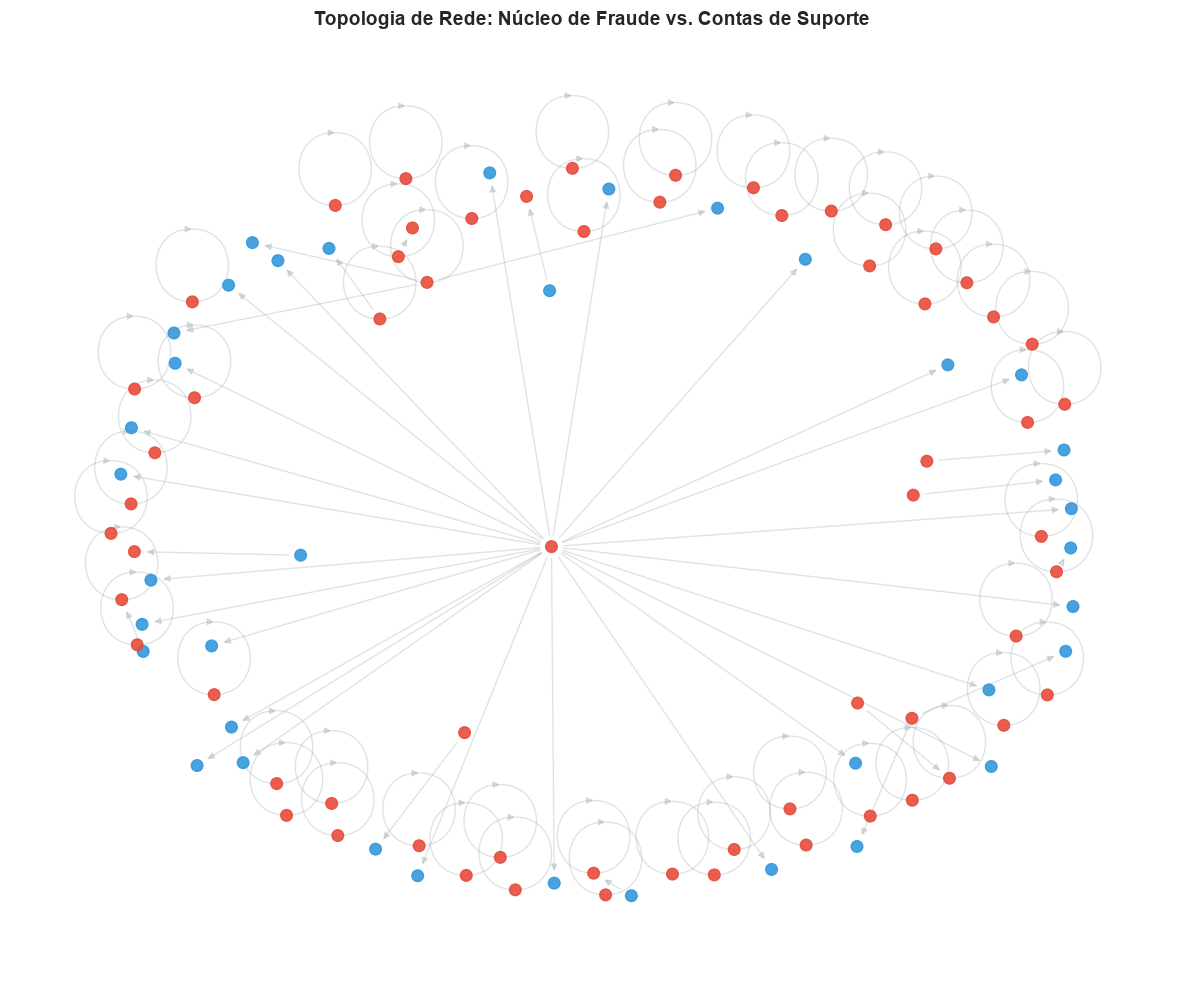

In [11]:
print("Gerando a visualização limpa da rede de crimes financeiros.")

# Pegamos uma amostra menor de arestas da nossa rede para o plot não virar uma mancha
sample_df = df_rede.head(150)

# Criamos um subgrafo temporário para essa amostra
G_sample = nx.from_pandas_edgelist(
    sample_df, source='Account', target='Target_Account', create_using=nx.DiGraph() # type: ignore 
) 

# Identificamos quais nós dessa amostra possuem flag de lavagem de dinheiro nas transações originais
fraud_account_set = set(df_rede[df_rede['Is_Laundering'] == 1]['Account']).union(
    set(df_rede[df_rede['Is_Laundering'] == 1]['Target_Account'])
) 

plt.figure(figsize=(12, 10))
pos = nx.spring_layout(G_sample, seed=42, k=0.2)

# Cores: Vermelho para contas envolvidas em fraude, Azul para contas de suporte/legítimas
node_colors = ['#e74c3c' if node in fraud_account_set else '#3498db' for node in G_sample.nodes()]

# Plotando com destaque limpo
nx.draw_networkx_nodes(G_sample, pos, node_size=70, node_color=node_colors, alpha=0.9)
nx.draw_networkx_edges(G_sample, pos, alpha=0.3, edge_color='#95a5a6', arrows=True, arrowsize=10)

plt.title("Topologia de Rede: Núcleo de Fraude vs. Contas de Suporte", fontsize=14, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

A visualização do gráfico acima deixa clara a nossa tese: a lavagem de dinheiro não ocorre de forma isolada, mas sim em **clusters interconectados**. Os pontos vermelhos representam o núcleo ilícito, cercados por contas intermediárias que formam a teia de dispersão e ocultação de capitais.

#### Anatomia do Crime: Coletores, Dispersores, Influenciadores e Pontes

Para entender o comportamento tático de cada conta na sub-rede, vamos cruzar todas as métricas estruturais que extraímos:

- **High In-Degree:** Contas que funcionam como *coletores* (recebem transações de múltiplas origens, típico de *smurfing*).

- **High Out-Degree:** Contas que funcionam como *dispersores* (espalham capital rapidamente para ocultar o rastro).

- **High PageRank:** Contas de **alta influência sistêmica** (nós que acumulam relevância por estarem conectados a outras contas importantes na rede).

- **High Betweenness:** As *pontes* críticas que conectam sub-redes distintas (*mule accounts*).

In [12]:
# Transformando os atributos já injetados no grafo em um DataFrame consolidado
df_nodes_metrics = pd.DataFrame([
    {
        'Account': node,
        'PageRank': data.get('pagerank', 0),
        'Betweenness': data.get('betweenness', 0),
        'In_Degree': data.get('in_degree', 0),
        'Out_Degree': data.get('out_degree', 0)
    }
    for node, data in G.nodes(data=True)
])

print("Top 5 Contas com Maior In-Degree (Maiores Coletores de Fundos):")
display(df_nodes_metrics.sort_values(by='In_Degree', ascending=False).head(5))

print("\nTop 5 Contas com Maior Out-Degree (Maiores Dispersores de Capital):")
display(df_nodes_metrics.sort_values(by='Out_Degree', ascending=False).head(5))

print("\nTop 5 Contas com Maior PageRank (Maiores Influenciadores Sistêmicos):")
display(df_nodes_metrics.sort_values(by='PageRank', ascending=False).head(5))

print("\nTop 5 Contas com Maior Betweenness (Contas-Laranja / Mule Accounts):")
display(df_nodes_metrics.sort_values(by='Betweenness', ascending=False).head(5))

Top 5 Contas com Maior In-Degree (Maiores Coletores de Fundos):


,Account,PageRank,Betweenness,In_Degree,Out_Degree
26074,801AF5660,0.003129,0.0,83,1
6669,80F523260,0.003133,0.0,83,1
6655,80F47A310,0.003030,0.0,80,1
4637,8007BC070,0.000575,0.0,79,0
4622,81484C700,0.002764,0.0,73,1



Top 5 Contas com Maior Out-Degree (Maiores Dispersores de Capital):


,Account,PageRank,Betweenness,In_Degree,Out_Degree
11,100428660,0.000008,0.0,0,14230
2746,1004286A8,0.000008,0.0,0,8846
6423,100428978,0.000008,0.0,0,1776
4639,1004286F0,0.000008,0.0,0,1575
6736,1004289C0,0.000008,0.0,0,1432



Top 5 Contas com Maior PageRank (Maiores Influenciadores Sistêmicos):


,Account,PageRank,Betweenness,In_Degree,Out_Degree
6669,80F523260,0.003133,0.0,83,1
26074,801AF5660,0.003129,0.0,83,1
6655,80F47A310,0.003030,0.0,80,1
4622,81484C700,0.002764,0.0,73,1
1214,806CF7480,0.002708,0.0,72,1



Top 5 Contas com Maior Betweenness (Contas-Laranja / Mule Accounts):


,Account,PageRank,Betweenness,In_Degree,Out_Degree
5240,80543A870,0.000092,6.802602e-07,6,2
430,801774BC0,0.000050,6.802602e-07,3,2
213,800A624A0,0.000049,6.453751e-07,3,4
5534,8064773A0,0.000072,6.453751e-07,4,5
8806,800FF9AA0,0.000029,6.104900e-07,3,4


###  Conclusão Fase 3: A Anatomia da Rede Exposta

A construção da sub-rede de risco e a extração das métricas topológicas nos deram a visibilidade estrutural que faltava:
- O **In-Degree e o Out-Degree** revelaram os papéis táticos dos atores: identificamos quais contas funcionam como *coletores* de capital fracionado (*smurfing*) e quais atuam como *dispersores* em massa para ocultar o rastro do dinheiro.

- O **PageRank** destacou os nós de maior relevância sistêmica no fluxo financeiro.
- A **Betweenness Centrality** isolou com precisão as contas que atuam como pontes e intermediárias obrigatórias (*mule accounts*) na teia criminosa.

---

Agora que mapeamos o DNA comportamental e estrutural da rede, podemos iniciar a última etapa: consolidar essas métricas topológicas junto aos dados tabulares originais e treinar nosso modelo preditivo final (**Graph-Enhanced Machine Learning**) na **Fase 4 (`04_modelagem_preditiva.ipynb`)**.

#### Salvando em uma nova tabela SQLite 

In [13]:
print("Persistindo as métricas topológicas de volta no banco SQLite.")

# Garantindo que o DataFrame está completo com todas as métricas
df_nodes_metrics = pd.DataFrame([
    {
        'Account': node,
        'PageRank': data.get('pagerank', 0),
        'Betweenness': data.get('betweenness', 0),
        'In_Degree': data.get('in_degree', 0),
        'Out_Degree': data.get('out_degree', 0)
    }
    for node, data in G.nodes(data=True)
])

# Salvando em uma nova tabela no SQLite (se já existir, substitui)
df_nodes_metrics.to_sql('contas_metricas_topologicas', conn, if_exists='replace', index=False)

# Fechando a conexão com segurança
conn.close()

print("Tabela 'contas_metricas_topologicas' criada e salva no banco SQLite.")
print("Notebook 03 concluído e pronto para alimentar a modelagem da Fase 4!")

Persistindo as métricas topológicas de volta no banco SQLite.
Tabela 'contas_metricas_topologicas' criada e salva no banco SQLite.
Notebook 03 concluído e pronto para alimentar a modelagem da Fase 4!
